# Chia tập theo danh tính và thiết kế protocol đánh giá
**Đồ án CV nâng cao · Nhóm A/B/C · Cập nhật 28/10/2026**

Notebook tiếp nối EDA và QA đã được Claude biên tập. Mục tiêu là biến kết quả QA thành **bản chia tập có thể chạy lại và kiểm tra rò rỉ**, trước khi tạo đầu vào mô hình. Mọi phép chia bên dưới tính trực tiếp từ manifest và ràng buộc QA; không đọc lại một báo cáo có sẵn để thay cho phân tích.

**Trạng thái:** `draft_unconfirmed`. Bản nháp đã có danh sách ảnh cụ thể và kiểm tra bằng code; chưa có xác nhận độc lập của nhóm về danh tính, gallery và các đề xuất tạm giữ. Việc được yêu cầu làm tiếp cho phép chuẩn bị quy trình, không biến nhận xét của AI thành nhãn chuẩn. Raw, nhãn nguồn, notebook EDA/QA gốc và gói Claude được giữ nguyên.

**Quyết định triển khai:** tiếp tục DigiFace đang có để phát triển pipeline; ROF/MFR2 được dành cho đánh giá ảnh thật, ngoài fine-tune và hiệu chỉnh. DigiFace có điều kiện `synthetic_unannotated`: B1 và gallery nội bộ được gọi là **dữ liệu nền**, chưa gọi là ảnh rõ đã xác minh.

## 1. Cần trả lời điều gì ở bước này?

1. Nếu chỉ tạm cách ly các crop có blocker và bản trùng phụ, còn bao nhiêu ảnh/người? Những cờ chất lượng hoặc detector nào vẫn cần được giữ trong mẫu số?
2. Làm sao tách người train/validation/test, người known/unknown và gallery/query mà không dùng cùng ảnh, cùng cảnh hay cùng nhóm gần trùng ở hai vai trò?
3. Dữ liệu thật có đủ ảnh rõ để đăng ký không? Phần nào đã kiểm được bằng code, phần nào còn cần xác nhận?

Ở đây không chạy detector, không sinh augmentation, không tính embedding và không chọn threshold. Kiểm tra metadata của tập test nhằm bảo đảm protocol khả thi; không dùng kết quả recognition trên test để chọn cấu hình.

In [1]:
from __future__ import annotations
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone
import hashlib, json, os, platform, sys, time
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import Markdown, display

def find_root():
    configured = os.environ.get('CV_PROJECT_ROOT')
    candidates = [Path(configured)] if configured else []
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidates += [parent, parent/'Đồ Án/Codex Works/DoAn_CV_NangCao',
                       parent/'Codex Works/DoAn_CV_NangCao']
    for p in candidates:
        if (p/'ban_giao_nhom/protocol/Chia_tap_va_protocol_danh_gia.ipynb').is_file():
            return p.resolve()
    raise FileNotFoundError('Mở notebook trong bản dự án Codex Works hoặc đặt CV_PROJECT_ROOT.')

ROOT = find_root()
HERE = ROOT/'ban_giao_nhom/protocol'
QA = ROOT/'ban_giao_nhom/qa'
OUT = HERE/'notebook_outputs'
TAB, FIG = OUT/'tables', OUT/'figures'
for p in [OUT, TAB, FIG]: p.mkdir(parents=True, exist_ok=True)
SEED = 20261027
STATUS = 'draft_unconfirmed'
STARTED = time.perf_counter()
CONFIG = {
    'version': 'identity_protocol_draft_v2', 'seed': SEED,
    'train_identities': 1600, 'validation_identities': 200, 'test_identities': 200,
    'unknown_fraction': 0.5, 'gallery_images_per_known': 3,
    'monitor_images_per_training_identity': 4,
    'withhold_actions': ['hold_proposed', 'duplicate_secondary_proposed'],
    'review_required_policy': 'retain_with_flags',
    'external_sources': ['ROF', 'MFR2'], 'target_validation_fpir': 0.05,
    'rof_unknown_fraction': 0.2, 'rof_gallery_images_per_known': 3,
    'rof_unknown_selection': 'deterministic_identity_component_subset',
    'gallery_clean_verification': 'pending', 'frozen': False,
}

def sha(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for block in iter(lambda: f.read(2**20), b''): h.update(block)
    return h.hexdigest()

def save(df, name):
    df.to_csv(TAB/(name+'.csv'), index=False, encoding='utf-8-sig')
    return df

def write_json(obj, name):
    (OUT/name).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')

def finish(fig, name):
    for ext in ['png', 'svg']:
        fig.savefig(FIG/(name+'.'+ext), bbox_inches='tight', dpi=160)
    display(fig)
    plt.close(fig)

def vn(x, digits=0):
    return f'{x:,.{digits}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def rank_key(value, context):
    return hashlib.sha256(f'{SEED}|{context}|{value}'.encode('utf-8')).hexdigest()

def stable_order(values, context):
    return sorted(set(map(str, values)), key=lambda x: (rank_key(x, context), x))

plt.rcParams.update({'font.family': 'Arial', 'figure.dpi': 110,
                     'axes.unicode_minus': False, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 24)
ENV = {'python': platform.python_version(), 'pandas': pd.__version__,
       'numpy': np.__version__, 'matplotlib': importlib.metadata.version('matplotlib'),
       'pillow': importlib.metadata.version('pillow'), 'seed': SEED,
       'network_access': 'none', 'raw_write': False, 'recognition_run': False}
display(pd.DataFrame([ENV]).T.rename(columns={0:'Giá trị'}))

,Giá trị
python,3.11.9
pandas,2.2.3
numpy,1.26.4
matplotlib,3.9.4
pillow,10.2.0
seed,20261027
network_access,none
raw_write,False
recognition_run,False


### Quy tắc chạy lại

Chọn kernel Python 3.11 của môi trường đồ án rồi **Restart Kernel → Run All**. Các bảng/hình trong `notebook_outputs` là đầu ra tự sinh. Quyết định của nhóm nằm riêng ở `../qa/group_decisions.csv`; notebook không ghi đè tệp đó.

Seed cố định chưa đủ để tái lập nếu thứ tự dòng thay đổi. Vì vậy, thứ tự chọn được xác định bằng SHA-256 của `seed | ngữ cảnh | ID`, với ID làm tie-break. Không dùng `hash()` của Python, score detector, embedding, blur hay độ sáng để chọn split.

## 2. Khóa phiên bản đầu vào và kiểm tính toàn vẹn

Mỗi kết quả phải truy được về manifest QA, nhóm ảnh, cạnh rò rỉ, ứng viên alias và file pairs của MFR2. SHA-256 kiểm tệp đầu vào đã dùng, không thay cho việc xác minh người trong ảnh.

Notebook QA trước đó đã kiểm bytes ảnh và tái dựng crop. Lượt này **không quét lại toàn bộ pixel**; chỉ tính mới split/protocol từ các bảng có provenance, và hash ảnh minh họa thực sự mở ở phần 11. Vì vậy không gọi lượt này là một đợt QA ảnh toàn bộ mới.

In [2]:
INPUTS = {
    'manifest': QA/'notebook_outputs/tables/16_QA_manifest_proposed.csv',
    'groups': QA/'notebook_outputs/tables/15_group_constraints.csv',
    'edges': QA/'notebook_outputs/tables/15_leakage_edges.csv',
    'near_reviews': QA/'notebook_outputs/tables/14_pair_review_results.csv',
    'aliases': QA/'notebook_outputs/tables/12_alias_mapping_candidates.csv',
    'pairs': QA/'notebook_outputs/tables/13_mfr2_pairs.csv',
    'pair_source': ROOT/'data/raw/mfr2/mfr2/pairs.txt',
    'qa_notebook': QA/'QA_nhan_trung_bounding_box.ipynb',
    'qa_summary': QA/'notebook_outputs/qa_execution_summary.json',
    'group_decisions': QA/'group_decisions.csv',
}
for name in ['page_review_log.csv','pair_review_decisions.csv','case_review_decisions.csv','verified_source_assets.csv']:
    INPUTS['review_'+name.removesuffix('.csv')]=QA/name
fingerprints = save(pd.DataFrame([
    {'key': k, 'path': p.relative_to(ROOT).as_posix(), 'bytes': p.stat().st_size,
     'sha256': sha(p)} for k,p in INPUTS.items()
]), '01_input_fingerprints')
read = lambda key: pd.read_csv(INPUTS[key], dtype=str, keep_default_na=False)
M, G, E, N, ALIAS, PAIRS = [read(k) for k in ['manifest','groups','edges','near_reviews','aliases','pairs']]
qa_summary = json.loads(INPUTS['qa_summary'].read_text(encoding='utf-8'))
assert qa_summary['checks']=='PASS'
review_input_hashes=qa_summary['review_input_sha256']
assert 'group_decisions.csv' in review_input_hashes
for filename, expected_sha in review_input_hashes.items():
    assert sha(QA/filename)==expected_sha, f'Review input đã đổi: {filename}. Chạy lại QA trước protocol.'
assert M.image_id.is_unique and M.path.is_unique
assert G.image_id.is_unique and set(G.image_id)==set(M.image_id)
assert M.canonical_identity.eq(M.source+':'+M.identity).all()
assert M['split'].eq('unassigned').all()
assert M[['sha256','pixel_sha256','photo_group','leakage_group']].ne('').all().all()
group_check = M[['image_id','photo_group','leakage_group']].merge(
    G[['image_id','photo_group','leakage_group']], on='image_id', validate='one_to_one', suffixes=('_m','_g'))
assert all(group_check[f'{c}_m'].eq(group_check[f'{c}_g']).all() for c in ['photo_group','leakage_group'])
assert E.image_id_a.isin(M.image_id).all() and E.image_id_b.isin(M.image_id).all()
display(fingerprints[['key','bytes','sha256']])
display(M.groupby('source').agg(images=('image_id','size'), source_labels=('identity','nunique')))

,key,bytes,sha256
0,manifest,33783973,249cfd4c178e7fef4bd9665620a02b88d16469e8ed8820...
1,groups,10669475,db1d00c92f236618361ae1c28d2212405c29b969c9a3e2...
2,edges,93654,d34e071b45e2e4a042b94bca5cd57ff36f70d6584ee1d3...
3,near_reviews,214602,c047581fb9234cb06f70db73bfcb897464f6079c9f87c6...
4,aliases,429,7d5a3faf3deff894c4f9d471683e7f00772f6dfe92cb80...
5,pairs,177779,9394a8e1acb9a18769355c3d16f17c40c89685a846b449...
6,pair_source,19690,da10def2851afc8c07d7bc4a75f63960f654c4a0efdec3...
7,qa_notebook,17129217,cea44605dc2e3816e2851dbfda1ab530816a9f9e3346af...
8,qa_summary,2000,e08491c87c8c8db51309965afd2a7c38737afe64673133...
9,group_decisions,88,aecb197e76b8c0a4f20c3bf16a0a60c7464960062ef607...


,images,source_labels
source,,
DigiFace,80000,2000
MFR2,269,53
ROF,6711,182


## 3. Chính sách dùng dữ liệu: cách ly blocker, giữ ca khó

Chính sách mặc định của bản nháp:

- `hold_proposed`: cách ly crop hiện tại vì nhãn/box/condition hoặc nội dung còn blocker. Nhóm này có cả ca nhiều box chưa xác định người; không gọi tất cả là ảnh hỏng.
- `duplicate_secondary_proposed`: giữ ngoài bản nháp để một ảnh không có nhiều bản đại diện.
- `review_required`: **giữ lại kèm cờ**. Detector thất bại, crop sát và đuôi blur/brightness chưa đủ lý do loại ảnh. Nếu xóa các ca này trước đánh giá, hệ thống sẽ có vẻ tốt hơn do chỉ còn ảnh dễ.
- `candidate_no_detected_blocker`: giữ dạng ứng viên; trạng thái này không chứng nhận nhãn đúng.

Nếu sau này nhóm ghi `keep/hold/exclude/approve_proposal` có người duyệt, ngày và bằng chứng vào tệp input riêng, bản nháp sẽ phản ánh quyết định đó. Nhãn nguồn và `qa_action_proposed` vẫn được giữ để truy vết.

In [3]:
def apply_draft_policy(frame):
    result = frame.copy()
    result['draft_eligible'] = ~result.qa_action_proposed.isin(CONFIG['withhold_actions'])
    result['draft_reason'] = np.where(result.draft_eligible,
        'retained_candidate_or_flagged_review', 'withheld_QA_proposal')
    decisions = result.group_decision.fillna('')
    assert decisions.isin(['','approve_proposal','keep','hold','exclude']).all()
    reviewed = decisions.ne('')
    for col in ['reviewer_ABC','decision_reason','reviewed_at','evidence_reference']:
        assert result.loc[reviewed,col].str.strip().ne('').all(), f'Thiếu {col}'
    result.loc[decisions.eq('keep'), 'draft_eligible'] = True
    result.loc[decisions.isin(['hold','exclude']), 'draft_eligible'] = False
    result.loc[reviewed,'draft_reason'] = 'reviewed_input:'+decisions[reviewed]
    result['protocol_status'] = STATUS
    return result

P = apply_draft_policy(M)
usable = P[P.draft_eligible].copy()
excluded = P[~P.draft_eligible].copy()
save(excluded, '02_withheld_draft')
impact = P.groupby(['source','condition']).agg(
    original_images=('image_id','size'), draft_images=('draft_eligible','sum'))
impact['withheld_images'] = impact.original_images-impact.draft_images
impact['retained_fraction'] = impact.draft_images/impact.original_images
save(impact.reset_index(), '02_policy_impact')
review_retention = save(P[P.qa_action_proposed.eq('review_required')].groupby('source').agg(
    review_images=('image_id','size'), retained=('draft_eligible','sum')).reset_index(), '02_review_retention')
assert len(usable)+len(excluded)==len(M)
display(impact)
display(review_retention)
display(Markdown(f'Bản nháp giữ **{vn(len(usable))}/{vn(len(M))} ảnh**, cách ly **{vn(len(excluded))} ảnh** trong danh sách, không chuyển/xóa file. '
                 f'Có **{vn(P.group_decision.ne("").sum())} quyết định nhóm** được đọc từ input riêng.'))

original_images  draft_images  \
source   condition                                              
DigiFace synthetic_unannotated            80000         80000   
MFR2     clean                               98            98   
         masked                             171           171   
ROF      clean                             4356          3903   
         masked                             264           198   
         sunglasses                        2091          1724   

                                withheld_images  retained_fraction  
source   condition                                                  
DigiFace synthetic_unannotated                0           1.000000  
MFR2     clean                                0           1.000000  
         masked                               0           1.000000  
ROF      clean                              453           0.896006  
         masked                              66           0.750000  
         sunglasses                         367           0.824486

,source,review_images,retained
0,DigiFace,2448,2448
1,MFR2,22,22
2,ROF,476,476


Bản nháp giữ **86.094/86.980 ảnh**, cách ly **886 ảnh** trong danh sách, không chuyển/xóa file. Có **0 quyết định nhóm** được đọc từ input riêng.

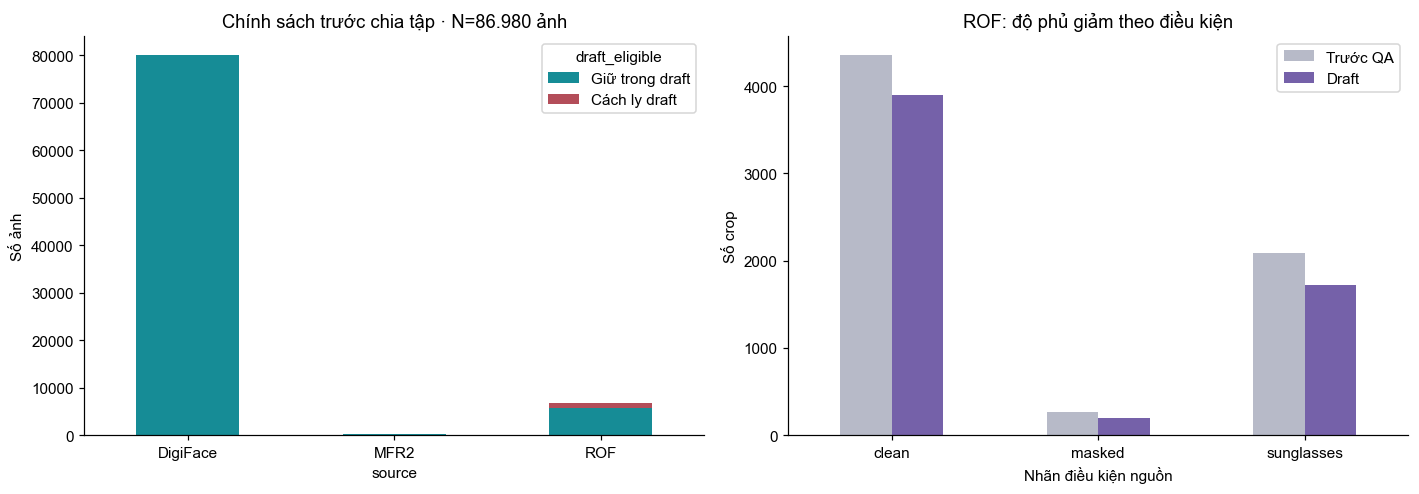

In [4]:
fig, axes = plt.subplots(1,2,figsize=(13,4.6))
counts = P.groupby(['source','draft_eligible']).size().unstack(fill_value=0)
counts.reindex(columns=[True,False],fill_value=0).rename(columns={True:'Giữ trong draft',False:'Cách ly draft'}).plot.bar(
    stacked=True, ax=axes[0], color=['#168C96','#B34D59'], rot=0)
axes[0].set(title=f'Chính sách trước chia tập · N={vn(len(M))} ảnh', ylabel='Số ảnh')
rof_impact = impact.loc['ROF'][['original_images','draft_images']].rename(
    columns={'original_images':'Trước QA','draft_images':'Draft'})
rof_impact.plot.bar(ax=axes[1],color=['#B7BAC8','#7561A9'],rot=0)
axes[1].set(title='ROF: độ phủ giảm theo điều kiện',ylabel='Số crop',xlabel='Nhãn điều kiện nguồn')
fig.tight_layout()
finish(fig,'02_policy_and_coverage')

### Vì sao không lọc mọi ảnh cần review?

Phần lớn cờ DigiFace là đuôi chất lượng proxy; cờ detector chỉ có trên mẫu đã audit. Lọc theo cờ này vừa loại ảnh khó vừa áp dụng quy tắc không đồng đều giữa ảnh đã/ chưa audit. Bản nháp giữ các ca đó, để preprocessing và evaluator sau này ghi lỗi bằng status, không làm biến mất khỏi mẫu số.

ROF đã mất nhiều crop khẩu trang do link chết và QA cấu trúc. Khi báo cáo phải đưa cả số ban đầu, số còn sau chính sách và lý do. Đây là subset crawl đã QA theo quy tắc công bố, chưa phải toàn bộ benchmark tác giả.

## 4. Đơn vị chống rò rỉ: danh tính, ảnh và cảnh

`canonical_identity=source:identity` chỉ là namespace nhãn nguồn. **photo_group** nối các bản cùng ảnh đã xác nhận; **leakage_group** nối thêm các crop chung ảnh/cảnh. Hai người đứng trong cùng cảnh không được gộp thành một danh tính, nhưng cảnh đó không nên vượt gallery/query.

Các cặp gần trùng chưa chắc chắn được thêm vào **guard group** để kiểm rò rỉ một cách bảo thủ, không được coi là chứng minh cùng người. Trước khi chia train/val/test, kiểm xem guard group có nối nhiều identity DigiFace không. Nếu có thì dừng: không chia ngẫu nhiên từng người và bỏ qua xung đột.

In [5]:
class DSU:
    def __init__(self, items): self.parent={x:x for x in items}
    def find(self, x):
        while self.parent[x]!=x:
            self.parent[x]=self.parent[self.parent[x]]
            x=self.parent[x]
        return x
    def union(self,a,b):
        a,b=self.find(a),self.find(b)
        if a!=b: self.parent[max(a,b)]=min(a,b)

guard = DSU(M.image_id)
for _, group in M.groupby('leakage_group',sort=False):
    ids=group.image_id.tolist()
    for image_id in ids[1:]: guard.union(ids[0],image_id)
pending = N[N.finding.isin(['pending','uncertain']) & N.has_flat.eq('False') & N.pixel_equal.eq('False')]
for row in pending.itertuples(): guard.union(row.image_id_a,row.image_id_b)
members=defaultdict(list)
for x in M.image_id: members[guard.find(x)].append(x)
guard_ids={x:'GUARD_'+hashlib.sha256('|'.join(sorted(xs)).encode()).hexdigest()[:20]
           for xs in members.values() for x in xs}
P['guard_group']=P.image_id.map(guard_ids)
usable=P[P.draft_eligible].copy()
shared=save(usable.groupby(['source','leakage_group']).agg(
    images=('image_id','size'),identities=('canonical_identity','nunique'),
    identity_list=('canonical_identity',lambda x:'|'.join(sorted(set(x)))))
    .query('identities>1').reset_index(), '03_shared_scenes_across_labels')
df_source=usable[usable.source.eq('DigiFace')].copy()
assert df_source.groupby('guard_group').canonical_identity.nunique().max()==1, 'Cần chia component ID trước'
assert df_source.groupby('canonical_identity').guard_group.nunique().ge(8).all()
save(P[['image_id','source','canonical_identity','photo_group','leakage_group','guard_group']], '03_guard_groups')
display(shared)
display(Markdown(f'Đã thêm **{vn(len(pending))} cạnh gần trùng chưa chắc** vào guard. '
                 'Không có guard group DigiFace vượt danh tính trong dữ liệu hiện tại. '
                 'Bảng cảnh chung cho thấy kiểm photo_group đơn lẻ chưa đủ.'))

,source,leakage_group,images,identities,identity_list
0,ROF,SCENE_c01ffea1be5df8a2,2,2,ROF:al_pacino|ROF:robert_de_niro


Đã thêm **15 cạnh gần trùng chưa chắc** vào guard. Không có guard group DigiFace vượt danh tính trong dữ liệu hiện tại. Bảng cảnh chung cho thấy kiểm photo_group đơn lẻ chưa đủ.

## 5. Chia 2.000 danh tính DigiFace: 1.600 / 200 / 200

Theo quy mô pilot trong kế hoạch, bản nháp dùng 80% danh tính train, 10% validation và 10% test. Tỷ lệ là lựa chọn thiết kế, không phải kết quả tối ưu. Người validation/test hoàn toàn không thuộc fine-tune; “người mới” ở đây chỉ nói về fine-tune của đồ án, không khẳng định về pretraining VGGFace2.

Train-monitor dùng 4 nhóm ảnh/identity train để quan sát overfit. Nó cùng danh tính với train nên không thay cho validation người mới. Val/test mỗi tập chia 100 known và 100 unknown theo danh tính. Unknown không có template trong gallery.

In [6]:
def allocate_identities(frame):
    ids=stable_order(frame.canonical_identity,'identity_partition')
    required=sum(CONFIG[k] for k in ['train_identities','validation_identities','test_identities'])
    if len(ids)!=required:
        raise ValueError(f'Cấu hình yêu cầu {required} identity, dữ liệu có {len(ids)}; cần phiên bản protocol mới.')
    cut1=CONFIG['train_identities']; cut2=cut1+CONFIG['validation_identities']
    rows=[]
    for partition,block in [('train',ids[:cut1]),('val',ids[cut1:cut2]),('test',ids[cut2:])]:
        unknown=set()
        if partition!='train':
            n_unknown=round(len(block)*CONFIG['unknown_fraction'])
            unknown=set(stable_order(block,partition+'_known_unknown')[:n_unknown])
        for identity in sorted(block):
            role='training_identity' if partition=='train' else ('unknown' if identity in unknown else 'known')
            rows.append({'canonical_identity':identity,'partition':partition,'identity_role':role})
    return pd.DataFrame(rows).sort_values('canonical_identity').reset_index(drop=True)

identity_split=allocate_identities(df_source)
assert identity_split.canonical_identity.is_unique
save(identity_split,'04_identity_splits_draft')
display(pd.crosstab(identity_split.partition,identity_split.identity_role))
display(Markdown('Mỗi identity được chọn bằng thứ tự SHA-256 cố định. Không phân tầng theo detector hay chất lượng ảnh; '
                 'mọi ảnh của một identity kế thừa partition này.'))

identity_role,known,training_identity,unknown
partition,,,
test,100,0,100
train,0,1600,0
val,100,0,100


Mỗi identity được chọn bằng thứ tự SHA-256 cố định. Không phân tầng theo detector hay chất lượng ảnh; mọi ảnh của một identity kế thừa partition này.

## 6. Gán vai trò từng ảnh mà không tách nhóm cảnh

Trong train, chọn 4 **guard group** làm monitor; các group còn lại làm train. Trong val/test, known có 3 group làm gallery và các group còn lại làm query; unknown đưa mọi ảnh vào unknown-query. Nếu một group có nhiều ảnh, chỉ một ảnh đại diện được dùng để enroll; ảnh còn lại của chính group đó phải mang vai trò reserve, không chuyển sang query.

Dữ liệu DigiFace hiện tại có 40 ảnh và 40 guard group mỗi người, nên số ảnh đúng bằng số group. Code vẫn xử lý trường hợp group có nhiều ảnh. Nếu sau QA một identity không đủ group, notebook báo lỗi, không âm thầm đổi mẫu.

In [7]:
def assign_image_roles(frame, splits):
    base=frame.merge(splits,on='canonical_identity',how='left',validate='many_to_one')
    rows=[]
    for identity,g in base.groupby('canonical_identity',sort=True):
        partition=g.partition.iloc[0]; identity_role=g.identity_role.iloc[0]
        ordered=stable_order(g.guard_group,identity+'_image_roles')
        if partition=='train':
            need=CONFIG['monitor_images_per_training_identity']
            if len(ordered)<=need: raise ValueError('Không đủ group train/monitor: '+identity)
            monitor=set(ordered[:need]);gallery=set()
        elif identity_role=='known':
            need=CONFIG['gallery_images_per_known']
            if len(ordered)<=need: raise ValueError('Không đủ group gallery/query: '+identity)
            gallery=set(ordered[:need]);monitor=set()
        else: gallery=set();monitor=set()
        image_records=g.to_dict('records')
        grouped=defaultdict(list)
        for r in image_records: grouped[r['guard_group']].append(r['image_id'])
        representatives={group_id:stable_order(ids,identity+'_representative')[0]
                         for group_id,ids in grouped.items()}
        for r in image_records:
            group_id=r['guard_group']
            if partition=='train': role='train_monitor' if group_id in monitor else 'train'
            elif identity_role=='unknown': role='unknown_query'
            elif group_id in gallery: role='gallery' if r['image_id']==representatives[group_id] else 'gallery_group_reserve'
            else: role='known_query'
            r.update(role=role,gallery_id=f"DigiFace_{partition}_g{CONFIG['gallery_images_per_known']}" if partition!='train' else '',
                     gallery_verification='pending_unannotated_base' if role=='gallery' else 'not_applicable')
            rows.append(r)
    return pd.DataFrame(rows).sort_values('image_id').reset_index(drop=True)

roles=assign_image_roles(df_source,identity_split)
assert roles.image_id.is_unique and len(roles)==len(df_source)
save(roles,'05_image_roles_draft')
role_summary=save(roles.groupby(['partition','role']).agg(
    images=('image_id','size'), identities=('canonical_identity','nunique'),
    review_flagged=('qa_action_proposed',lambda s:s.eq('review_required').sum())).reset_index(), '05_role_summary')
display(role_summary)

,partition,role,images,identities,review_flagged
0,test,gallery,300,100,5
1,test,known_query,3700,100,115
2,test,unknown_query,4000,100,111
3,train,train,57600,1600,1794
4,train,train_monitor,6400,1600,192
5,val,gallery,300,100,14
6,val,known_query,3700,100,102
7,val,unknown_query,4000,100,115


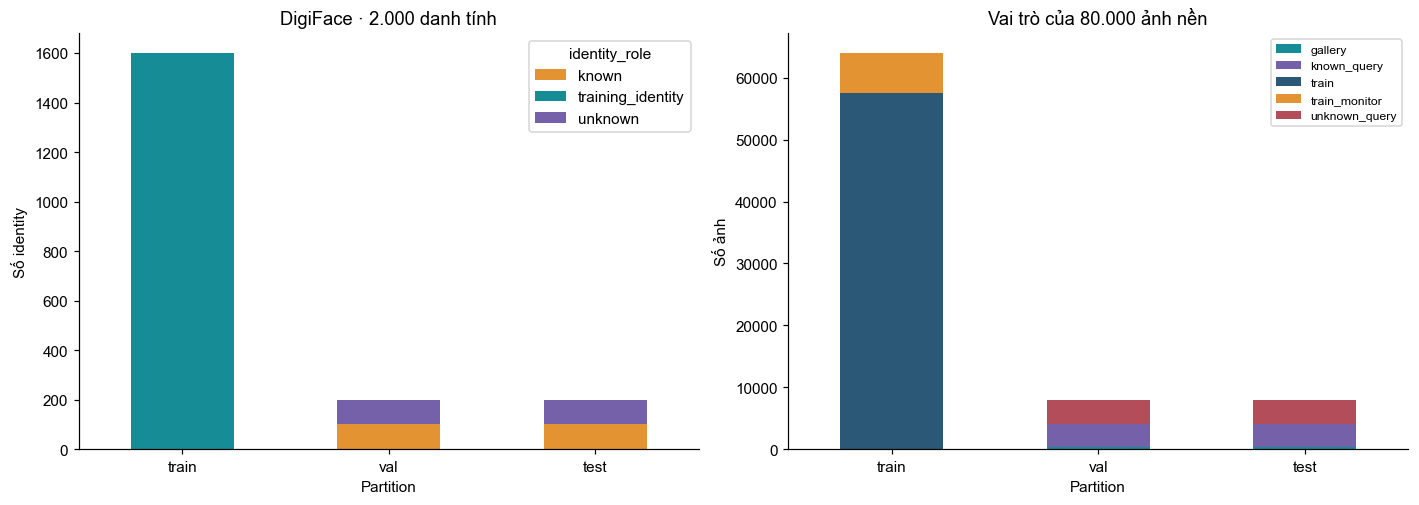

In [8]:
fig,axes=plt.subplots(1,2,figsize=(13,4.7))
pd.crosstab(identity_split.partition,identity_split.identity_role).reindex(['train','val','test']).plot.bar(
    stacked=True,ax=axes[0],color=['#E49332','#168C96','#7561A9'],rot=0)
axes[0].set(title=f'DigiFace · {vn(len(identity_split))} danh tính',ylabel='Số identity',xlabel='Partition')
pd.crosstab(roles.partition,roles.role).reindex(['train','val','test']).plot.bar(
    stacked=True,ax=axes[1],color=['#168C96','#7561A9','#2B5876','#E49332','#B34D59'],rot=0)
axes[1].set(title=f'Vai trò của {vn(len(roles))} ảnh nền',ylabel='Số ảnh',xlabel='Partition')
axes[1].legend(fontsize=8)
fig.tight_layout();finish(fig,'05_identity_and_image_roles')

### Ý nghĩa đối với B1/B2

Các ảnh `train_monitor` không cập nhật gradient. Nếu augmentation được thêm sau này, mọi biến thể phải kế thừa `image_id` nền, partition và group. B1/B2 dùng cùng ảnh nền train và cùng số optimizer steps; không đưa ảnh monitor, validation hoặc test vào train vì đã sinh thêm một file mới.

Val/test là ảnh tổng hợp chưa gán nhãn che. Kết quả tại đây trả lời khả năng khái quát **trong miền tổng hợp**; cần ROF/MFR2 và webcam độc lập để đánh giá chuyển sang ảnh thật. Gallery nội bộ hiện chưa được kiểm “mặt rõ”; nếu nhóm thay gallery sau khi xem ảnh, phải tăng protocol version và chạy lại các kiểm tra trước recognition.

## 7. Kiểm rò rỉ và thử xem bộ kiểm có bắt lỗi không

Không chỉ kiểm train/val/test giao nhau theo image ID. Phải kiểm identity, hash bytes, hash pixel, nhóm cùng ảnh, cảnh và guard group. Trong train, train/monitor tách ảnh/group; trong mỗi val/test, gallery không chung group với bất cứ query nào, kể cả query khác người.

Các ca âm ở cuối cell cố tình tạo lỗi trên **bản sao trong RAM**, để xác nhận bộ kiểm phát hiện rò rỉ danh tính, cảnh và unknown xuất hiện trong gallery. Không ghi các dữ liệu lỗi vào manifest.

In [9]:
def leakage_checks(frame):
    checks=[]
    def record(name,passed,detail=''):
        checks.append({'check':name,'passed':bool(passed),'detail':str(detail)})
    record('image_id_unique',frame.image_id.is_unique)
    record('every_image_assigned',frame.partition.isin(['train','val','test']).all() & frame.role.ne('').all())
    record('identity_partition_disjoint',frame.groupby('canonical_identity').partition.nunique().le(1).all())
    for col in ['sha256','pixel_sha256','photo_group','leakage_group','guard_group']:
        record(col+'_partition_disjoint',frame.groupby(col).partition.nunique().le(1).all())
        for part in ['train','val','test']:
            sub=frame[frame.partition.eq(part)]
            left_roles=['train'] if part=='train' else ['gallery','gallery_group_reserve']
            right_roles=['train_monitor'] if part=='train' else ['known_query','unknown_query']
            left=set(sub[sub.role.isin(left_roles)][col]);right=set(sub[sub.role.isin(right_roles)][col])
            record(f'{col}_{part}_role_disjoint',not (left&right),len(left&right))
    for part in ['val','test']:
        sub=frame[frame.partition.eq(part)]
        gallery_ids=set(sub[sub.role.eq('gallery')].canonical_identity)
        known_ids=set(sub[sub.role.eq('known_query')].canonical_identity)
        unknown_ids=set(sub[sub.role.eq('unknown_query')].canonical_identity)
        record(part+'_known_has_gallery',known_ids<=gallery_ids)
        record(part+'_unknown_absent_gallery',not (unknown_ids&gallery_ids))
        record(part+'_known_unknown_disjoint',not (known_ids&unknown_ids))
        gallery_count=sub[sub.role.eq('gallery')].groupby('canonical_identity').size()
        record(part+'_gallery_count_fixed',gallery_count.eq(CONFIG['gallery_images_per_known']).all())
    return pd.DataFrame(checks)

checks=leakage_checks(roles)
assert checks.passed.all(),checks[~checks.passed].to_dict('records')
save(checks,'06_leakage_assertions')
lookup_roles=roles.set_index('image_id')
for row in E.itertuples():
    # External không gán gallery/query ở bước này. Kiểm mọi cạnh nội bộ nếu có.
    if row.image_id_a in lookup_roles.index and row.image_id_b in lookup_roles.index:
        assert lookup_roles.loc[row.image_id_a,'partition']==lookup_roles.loc[row.image_id_b,'partition']

# Thứ tự input thay đổi vẫn phải sinh đúng cùng danh sách identity và vai trò ảnh.
shuffled=df_source.sample(frac=1,random_state=17)
pd.testing.assert_frame_equal(identity_split,allocate_identities(shuffled))
pd.testing.assert_frame_equal(roles,assign_image_roles(shuffled,identity_split))

bad_identity=roles.copy()
idx=bad_identity[bad_identity.partition.eq('train')].index[0]
bad_identity.loc[idx,'partition']='val'
bad_scene=roles.copy()
gidx=bad_scene[bad_scene.role.eq('gallery') & bad_scene.partition.eq('val')].index[0]
qidx=bad_scene[bad_scene.role.eq('known_query') & bad_scene.partition.eq('val')].index[0]
bad_scene.loc[qidx,'leakage_group']=bad_scene.loc[gidx,'leakage_group']
bad_unknown=roles.copy()
uidx=bad_unknown[bad_unknown.role.eq('unknown_query') & bad_unknown.partition.eq('val')].index[0]
bad_unknown.loc[uidx,'canonical_identity']=bad_unknown.loc[gidx,'canonical_identity']
negative_tests=[]
for label,broken,target in [
    ('identity chuyển một ảnh sang val',bad_identity,'identity_partition_disjoint'),
    ('cảnh chung gallery/query',bad_scene,'leakage_group_val_role_disjoint'),
    ('unknown xuất hiện trong gallery',bad_unknown,'val_unknown_absent_gallery')]:
    result=leakage_checks(broken).set_index('check')
    detected=not bool(result.loc[target,'passed'])
    assert detected
    negative_tests.append({'injected_error':label,'detected':detected})
save(pd.DataFrame(negative_tests),'06_negative_tests')
display(checks)
display(pd.DataFrame(negative_tests))

,check,passed,detail
0,image_id_unique,True,
1,every_image_assigned,True,
2,identity_partition_disjoint,True,
3,sha256_partition_disjoint,True,
4,sha256_train_role_disjoint,True,0
...,...,...,...
26,val_gallery_count_fixed,True,
27,test_known_has_gallery,True,
28,test_unknown_absent_gallery,True,
29,test_known_unknown_disjoint,True,


,injected_error,detected
0,identity chuyển một ảnh sang val,True
1,cảnh chung gallery/query,True
2,unknown xuất hiện trong gallery,True


## 8. Dữ liệu thật: dành ngoài tuning và đo tính khả thi

ROF và MFR2 được gán **external_test_reserve**, không chia sang train/validation, không dùng để chọn preprocessing, augmentation, epoch hoặc threshold. Ở bước này chỉ tính metadata, độ phủ và các vai trò gallery/query dự thảo theo quy tắc cố định; chưa chạy nhận diện hoặc chọn gallery theo score.

ROF dùng gallery có nhãn nguồn `clean` nhưng vẫn cần kiểm bằng mắt. Bảng dưới đòi ít nhất `g` **guard group clean** và ít nhất một query masked/sunglasses ở **group khác**. Một scene chứa cả clean và masked không được tính như hai quan sát độc lập.

Với MFR2, giữ nguyên file pairs chính thức; bảng gallery chỉ là phương án tùy chỉnh để so tính khả thi, không thay thế protocol verification của tác giả. Người thiếu ảnh gallery là **không đủ điều kiện protocol đó**, không tự đổi thành unknown.

In [10]:
external=usable[usable.source.isin(CONFIG['external_sources'])].copy()
external['partition']='external_test_reserve'
external['role']='reserve_not_yet_enrolled'
save(external,'07_external_test_reserve')

def external_feasibility(frame):
    results=[]
    for (source,identity),group in frame.groupby(['source','canonical_identity']):
        clean=set(group[group.condition.eq('clean')].guard_group)
        mixed=set(group.groupby('guard_group').condition.nunique().loc[lambda s:s>1].index)
        # Không dùng group có nhiều condition làm gallery clean trong bản nháp.
        clean_safe=clean-mixed
        for g in [1,2,3]:
            enough=len(clean_safe)>=g
            chosen=set(stable_order(clean_safe,identity+f'_external_g{g}')[:g]) if enough else set()
            for condition in ['masked','sunglasses']:
                query=group[group.condition.eq(condition) & ~group.guard_group.isin(chosen)] if enough else group.iloc[:0]
                results.append({'source':source,'canonical_identity':identity,'gallery_size_per_identity':g,
                    'query_condition':condition,'clean_groups':len(clean_safe),
                    'eligible':bool(enough and len(query)>0),'available_queries':len(query)})
    return pd.DataFrame(results)

feasible=external_feasibility(external)
save(feasible,'07_external_feasibility_per_identity')
feasibility=save(feasible.groupby(['source','gallery_size_per_identity','query_condition']).agg(
    eligible_identities=('eligible','sum'),available_queries=('available_queries','sum')).reset_index(), '07_external_feasibility_summary')
display(feasibility)
display(pd.crosstab(external.source,external.condition))
display(Markdown('Đây là phép đếm tính khả thi theo nhãn nguồn. Chưa có gallery external chính thức, '
                 'chưa xác nhận ảnh rõ, chưa khẳng định mỗi tên nguồn là một danh tính đúng.'))

,source,gallery_size_per_identity,query_condition,eligible_identities,available_queries
0,MFR2,1,masked,53,171
1,MFR2,1,sunglasses,0,0
2,MFR2,2,masked,45,152
3,MFR2,2,sunglasses,0,0
4,MFR2,3,masked,0,0
5,MFR2,3,sunglasses,0,0
6,ROF,1,masked,55,198
7,ROF,1,sunglasses,155,1708
8,ROF,2,masked,55,198
9,ROF,2,sunglasses,155,1708


condition,clean,masked,sunglasses
source,,,
MFR2,98,171,0
ROF,3903,198,1724


Đây là phép đếm tính khả thi theo nhãn nguồn. Chưa có gallery external chính thức, chưa xác nhận ảnh rõ, chưa khẳng định mỗi tên nguồn là một danh tính đúng.

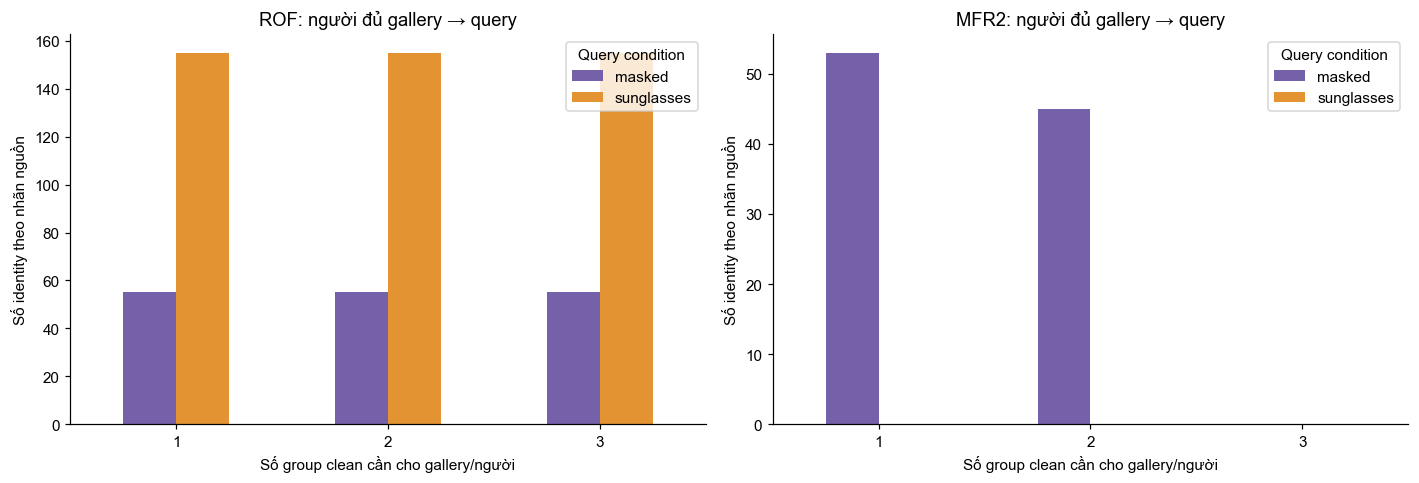

In [11]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,source in zip(axes,['ROF','MFR2']):
    sub=feasibility[feasibility.source.eq(source)]
    pivot=sub.pivot(index='gallery_size_per_identity',columns='query_condition',values='eligible_identities')
    pivot.plot.bar(ax=ax,color=['#7561A9','#E49332'],rot=0)
    ax.set(title=f'{source}: người đủ gallery → query',xlabel='Số group clean cần cho gallery/người',ylabel='Số identity theo nhãn nguồn')
    ax.legend(title='Query condition')
fig.tight_layout();finish(fig,'07_external_gallery_feasibility')

### 8.1. Tạo cohort ROF 1:N cụ thể, vẫn giữ ngoài tuning

Bảng feasibility chưa đủ để viết loader hay chỉ ra ảnh nhóm cần duyệt. Phần này tạo vai trò từng ảnh theo metadata trước mọi kết quả nhận diện:

1. Identity ứng viên phải có ít nhất 3 **guard group clean an toàn cho gallery** và còn ít nhất một group khác để làm query. Group an toàn chỉ chứa một identity và duy nhất condition `clean` trong cohort còn dùng. Group chung cảnh giữa hai nhãn không được chọn làm gallery.
2. Các identity chung guard group được nối thành **identity component chống rò rỉ**, giữ nguyên nhãn từng người. Component được phân toàn bộ về known hoặc unknown. Chọn khoảng 20% **identity đủ điều kiện** làm unknown bằng thứ tự hash cố định, giải bài toán tổng kích thước component để đạt đúng số mục tiêu khi khả thi. Không dùng score, chất lượng hoặc kết quả detector.
3. Known: chọn 3 group clean an toàn và một ảnh đại diện mỗi group; mọi group khác là known-query. Ảnh khác cùng group gallery được giữ ở reserve, không đi sang query. Unknown: mọi ảnh hiện có là unknown-query và không có template. Identity thiếu gallery giữ ở `ineligible_protocol_reserve`, **không tự biến thành người lạ**.

Đây là protocol tùy chỉnh trên bản ROF crawl đã QA theo chính sách công bố, chưa là benchmark tác giả hoặc gallery clean đã được nhóm xác nhận. Chia known/unknown làm thay đổi số query masked ở từng phía; phải báo mẫu số thực, không lấy toàn bộ masked làm số query known. Cờ detector/quality được giữ nguyên trong mọi vai trò.

In [12]:
def assign_rof_roles(frame):
    rof=frame[frame.source.eq('ROF')].copy()
    g=CONFIG['rof_gallery_images_per_known']
    stats=rof.groupby('guard_group').agg(
        identities=('canonical_identity','nunique'),conditions=('condition','nunique'))
    safe=set(stats[(stats.identities==1)&(stats.conditions==1)].index)
    eligibility=[]
    for identity,person in rof.groupby('canonical_identity',sort=True):
        clean=set(person[person.condition.eq('clean') & person.guard_group.isin(safe)].guard_group)
        all_groups=set(person.guard_group)
        eligible=len(clean)>=g and len(all_groups)>g
        eligibility.append({'canonical_identity':identity,'source_images':len(person),
            'safe_clean_groups':len(clean),'all_guard_groups':len(all_groups),'eligible':eligible,
            'ineligible_reason':'' if eligible else ('insufficient_clean_gallery_groups' if len(clean)<g else 'no_independent_query_group')})
    eligibility=pd.DataFrame(eligibility)
    eligible_ids=set(eligibility[eligibility.eligible].canonical_identity)

    # Nối identity để ràng buộc phía known/unknown; đây không phải phép gộp danh tính.
    components=DSU(rof.canonical_identity.unique())
    for _,scene in rof.groupby('guard_group',sort=False):
        ids=sorted(set(scene.canonical_identity))
        for identity in ids[1:]: components.union(ids[0],identity)
    component_members=defaultdict(list)
    for identity in rof.canonical_identity.unique(): component_members[components.find(identity)].append(identity)
    component_id={identity:'IDCOMP_'+hashlib.sha256('|'.join(sorted(ids)).encode()).hexdigest()[:20]
                  for ids in component_members.values() for identity in ids}
    eligible_by_component=defaultdict(list)
    for identity in sorted(eligible_ids): eligible_by_component[component_id[identity]].append(identity)
    ordered_components=stable_order(eligible_by_component,'ROF_known_unknown_components')
    target_unknown=round(len(eligible_ids)*CONFIG['rof_unknown_fraction'])
    # Subset-sum theo thứ tự cố định, không tách component chỉ để đạt tỷ lệ.
    reachable={0:[]}
    for component in ordered_components:
        size=len(eligible_by_component[component])
        previous=list(reachable.items())
        for count,chosen in previous:
            new=count+size
            if new not in reachable: reachable[new]=chosen+[component]
    achieved=min(reachable,key=lambda n:(abs(n-target_unknown),n))
    unknown_components=set(reachable[achieved])
    unknown_ids={identity for component in unknown_components for identity in eligible_by_component[component]}
    rows=[]
    for identity,person in rof.groupby('canonical_identity',sort=True):
        is_eligible=identity in eligible_ids
        identity_role='unknown' if identity in unknown_ids else ('known' if is_eligible else 'ineligible')
        chosen=set()
        if identity_role=='known':
            clean=set(person[person.condition.eq('clean')&person.guard_group.isin(safe)].guard_group)
            chosen=set(stable_order(clean,identity+'_ROF_gallery')[:g])
        records=person.to_dict('records');group_members=defaultdict(list)
        for r in records: group_members[r['guard_group']].append(r['image_id'])
        representatives={group:stable_order(ids,identity+'_ROF_gallery_representative')[0]
                         for group,ids in group_members.items()}
        reason=eligibility.set_index('canonical_identity').loc[identity,'ineligible_reason']
        for r in records:
            if identity_role=='ineligible': role='ineligible_protocol_reserve'
            elif identity_role=='unknown': role='unknown_query'
            elif r['guard_group'] in chosen:
                role='gallery' if r['image_id']==representatives[r['guard_group']] else 'gallery_group_reserve'
            else: role='known_query'
            r.update(partition='external_test_reserve',role=role,identity_role=identity_role,
                identity_component=component_id[identity],
                gallery_id=f'ROF_external_g{g}_draft',
                gallery_verification='pending_source_clean_label' if role=='gallery' else 'not_applicable',
                eligibility_reason=reason)
            rows.append(r)
    result=pd.DataFrame(rows).sort_values('image_id').reset_index(drop=True)
    identities=eligibility.copy()
    identities['identity_component']=identities.canonical_identity.map(component_id)
    identities['identity_role']=identities.canonical_identity.map(
        result.drop_duplicates('canonical_identity').set_index('canonical_identity').identity_role)
    identities['partition']='external_test_reserve'
    details={'eligible_identities':len(eligible_ids),'target_unknown_identities':target_unknown,
        'actual_unknown_identities':len(unknown_ids),'unknown_components':len(unknown_components),
        'known_identities':len(eligible_ids)-len(unknown_ids),
        'ineligible_identities':len(identities)-len(eligible_ids),'component_split_allowed':False}
    return result,identities.sort_values('canonical_identity').reset_index(drop=True),details

rof_roles,rof_identity_roles,rof_allocation=assign_rof_roles(external)
save(rof_roles,'07_rof_image_roles_draft')
save(rof_identity_roles,'07_rof_identity_roles_draft')
rof_role_summary=save(rof_roles.groupby(['identity_role','role','condition']).agg(
    images=('image_id','size'),identities=('canonical_identity','nunique'),
    review_flagged=('qa_action_proposed',lambda x:x.eq('review_required').sum())).reset_index(), '07_rof_role_summary')
display(pd.DataFrame([rof_allocation]))
display(rof_identity_roles[~rof_identity_roles.eligible])
display(rof_role_summary)

,eligible_identities,target_unknown_identities,actual_unknown_identities,unknown_components,known_identities,ineligible_identities,component_split_allowed
0,180,36,36,36,144,2,False


,canonical_identity,source_images,safe_clean_groups,all_guard_groups,eligible,ineligible_reason,identity_component,identity_role,partition
34,ROF:daniil_medvedev,2,2,2,False,insufficient_clean_gallery_groups,IDCOMP_05911e18a396a598c246,ineligible,external_test_reserve
176,ROF:will_smith,16,0,16,False,insufficient_clean_gallery_groups,IDCOMP_b252f132fbd650a605fb,ineligible,external_test_reserve


,identity_role,role,condition,images,identities,review_flagged
0,ineligible,ineligible_protocol_reserve,clean,2,1,0
1,ineligible,ineligible_protocol_reserve,sunglasses,16,1,2
2,known,gallery,clean,432,144,24
3,known,gallery_group_reserve,clean,1,1,0
4,known,known_query,clean,2693,144,171
5,known,known_query,masked,178,47,53
6,known,known_query,sunglasses,1432,126,133
7,unknown,unknown_query,clean,775,36,56
8,unknown,unknown_query,masked,20,8,4
9,unknown,unknown_query,sunglasses,276,29,33


### 8.2. Kiểm ROF gallery/query và known/unknown trên toàn cohort

Gallery/query tách theo ảnh và group **toàn nguồn**, không chỉ trong từng người. Một cảnh có hai nhãn khác nhau có thể vượt vai trò dù kiểm riêng từng identity đều đạt. Các scene chung được để ở query/reserve và giữ ràng buộc component cho known/unknown.

Các kiểm dưới đây cũng giữ đủ mọi crop còn dùng trong một vai trò, bảo toàn cờ review và từ chối đổi thiếu gallery thành unknown. Ba lỗi giả lập trên bản sao trong RAM kiểm rằng validator không chỉ báo PASS cho dữ liệu đã biết.

In [13]:
def rof_checks(frame, original):
    rows=[]
    def record(name,passed,detail=''):
        rows.append({'check':name,'passed':bool(passed),'detail':str(detail)})
    record('external_image_ids_exact',frame.image_id.is_unique and set(frame.image_id)==set(original.image_id))
    record('external_never_tuning',frame.partition.eq('external_test_reserve').all())
    record('identity_role_unique',frame.groupby('canonical_identity').identity_role.nunique().le(1).all())
    active=frame[frame.identity_role.isin(['known','unknown'])]
    record('component_known_unknown_not_split',active.groupby('identity_component').identity_role.nunique().le(1).all())
    gallery=frame[frame.role.eq('gallery')]
    queries=frame[frame.role.isin(['known_query','unknown_query'])]
    known_ids=set(frame[frame.identity_role.eq('known')].canonical_identity)
    unknown_ids=set(frame[frame.role.eq('unknown_query')].canonical_identity)
    record('unknown_absent_gallery',not (set(gallery.canonical_identity)&unknown_ids))
    record('every_known_has_gallery',known_ids==set(gallery.canonical_identity))
    record('gallery_size_fixed',gallery.groupby('canonical_identity').size().eq(CONFIG['rof_gallery_images_per_known']).all())
    record('gallery_condition_source_clean',gallery.condition.eq('clean').all())
    record('known_queries_remain',set(frame[frame.role.eq('known_query')].canonical_identity)==known_ids)
    for col in ['image_id','sha256','pixel_sha256','photo_group','leakage_group','guard_group']:
        common=set(gallery[col])&set(queries[col])
        record(col+'_gallery_query_disjoint',not common,len(common))
    guard_identities=original.groupby('guard_group').canonical_identity.nunique()
    record('gallery_no_cross_identity_guard',gallery.guard_group.map(guard_identities).eq(1).all())
    guard_conditions=original.groupby('guard_group').condition.nunique()
    record('gallery_no_mixed_condition_guard',gallery.guard_group.map(guard_conditions).eq(1).all())
    record('ineligible_never_unknown',frame[frame.eligibility_reason.ne('')].role.eq('ineligible_protocol_reserve').all())
    check_fields=['qa_reasons','qa_action_proposed','detector_audited','condition','canonical_identity','sha256']
    actual=frame.set_index('image_id');expected=original.set_index('image_id')
    record('QA_flags_and_source_labels_preserved',all(actual.loc[expected.index,c].eq(expected[c]).all() for c in check_fields))
    return pd.DataFrame(rows)

rof_original=external[external.source.eq('ROF')].copy()
external_checks=rof_checks(rof_roles,rof_original)
assert external_checks.passed.all(),external_checks[~external_checks.passed].to_dict('records')
save(external_checks,'07_rof_leakage_assertions')
shuffled_rof,shuffled_identities,shuffled_details=assign_rof_roles(external.sample(frac=1,random_state=71))
pd.testing.assert_frame_equal(rof_roles,shuffled_rof)
pd.testing.assert_frame_equal(rof_identity_roles,shuffled_identities)
assert rof_allocation==shuffled_details

gallery_idx=rof_roles[rof_roles.role.eq('gallery')].index[0]
query_idx=rof_roles[rof_roles.role.eq('known_query')].index[0]
unknown_idx=rof_roles[rof_roles.role.eq('unknown_query')].index[0]
bad_scene=rof_roles.copy();bad_scene.loc[query_idx,'guard_group']=bad_scene.loc[gallery_idx,'guard_group']
bad_unknown=rof_roles.copy();bad_unknown.loc[unknown_idx,'canonical_identity']=bad_unknown.loc[gallery_idx,'canonical_identity']
bad_count=rof_roles.copy();bad_count.loc[gallery_idx,'role']='known_query'
external_negative_tests=[]
for label,broken,target in [
    ('ROF cảnh chung gallery/query',bad_scene,'guard_group_gallery_query_disjoint'),
    ('ROF unknown có tên trong gallery',bad_unknown,'unknown_absent_gallery'),
    ('ROF mất một ảnh gallery đã chốt',bad_count,'gallery_size_fixed')]:
    result=rof_checks(broken,rof_original).set_index('check')
    detected=not bool(result.loc[target,'passed'])
    assert detected
    external_negative_tests.append({'injected_error':label,'detected':detected})
save(pd.DataFrame(external_negative_tests),'07_rof_negative_tests')

external_assigned=pd.concat([rof_roles,external[external.source.eq('MFR2')].assign(
    identity_role='official_verification_reserve',identity_component='',gallery_id='',
    gallery_verification='not_applicable',eligibility_reason='official_pairs_kept_separate')],ignore_index=True)
save(external_assigned,'07_external_image_roles_draft')
queue_internal=roles[roles.role.eq('gallery')].copy()
queue_internal['identity_component']=queue_internal.canonical_identity
queue_internal['review_scope']='gallery_base_condition_face_and_subject'
queue_rof=rof_roles[rof_roles.role.eq('gallery')].copy()
queue_rof['review_scope']='source_clean_gallery_face_and_subject'
gallery_review_queue=pd.concat([queue_internal,queue_rof],ignore_index=True)
gallery_review_queue['verification_status']='pending_independent_review'
queue_columns=['image_id','source','canonical_identity','condition','path','sha256','pixel_sha256',
    'photo_group','leakage_group','guard_group','partition','role','gallery_id','identity_component',
    'review_scope','verification_status']
save(gallery_review_queue[queue_columns].sort_values(['source','partition','canonical_identity','image_id']), '07_gallery_review_queue')
display(external_checks)
display(pd.DataFrame(external_negative_tests))
display(gallery_review_queue.groupby(['source','partition']).size().rename('images_to_review'))

,check,passed,detail
0,external_image_ids_exact,True,
1,external_never_tuning,True,
2,identity_role_unique,True,
3,component_known_unknown_not_split,True,
4,unknown_absent_gallery,True,
5,every_known_has_gallery,True,
6,gallery_size_fixed,True,
7,gallery_condition_source_clean,True,
8,known_queries_remain,True,
9,image_id_gallery_query_disjoint,True,0


,injected_error,detected
0,ROF cảnh chung gallery/query,True
1,ROF unknown có tên trong gallery,True
2,ROF mất một ảnh gallery đã chốt,True


source    partition            
DigiFace  test                     300
          val                      300
ROF       external_test_reserve    432
Name: images_to_review, dtype: int64

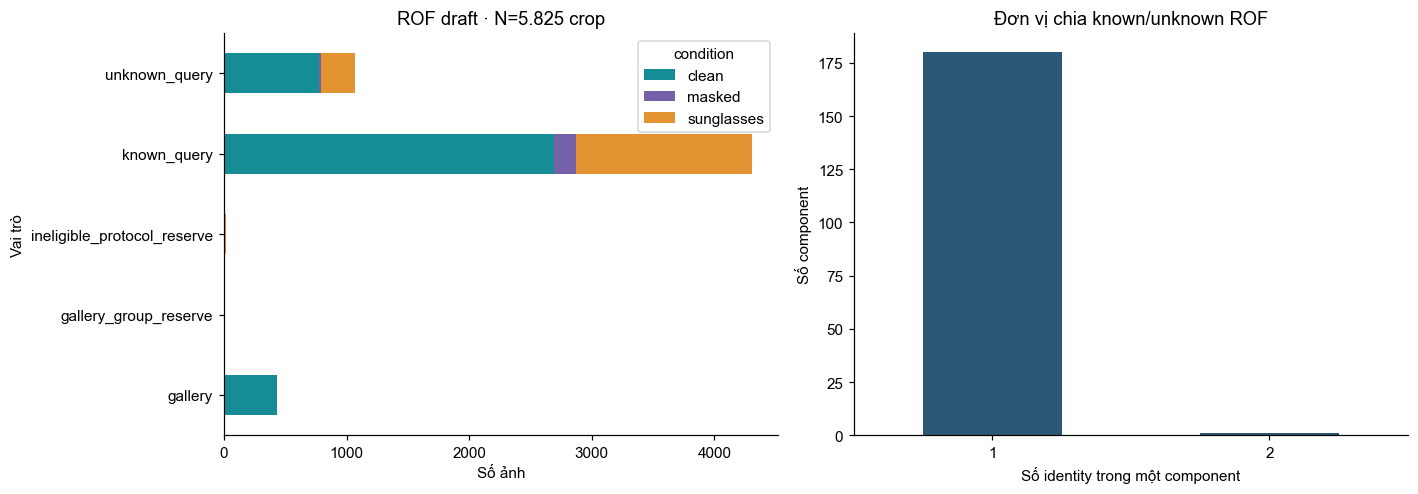

In [14]:
fig,axes=plt.subplots(1,2,figsize=(13,4.6))
pd.crosstab(rof_roles.role,rof_roles.condition).plot.barh(
    stacked=True,ax=axes[0],color=['#168C96','#7561A9','#E49332'])
axes[0].set(title=f'ROF draft · N={vn(len(rof_roles))} crop',xlabel='Số ảnh',ylabel='Vai trò')
component_sizes=rof_identity_roles.groupby('identity_component').size()
component_sizes.value_counts().sort_index().plot.bar(ax=axes[1],color='#2B5876',rot=0)
axes[1].set(title='Đơn vị chia known/unknown ROF',xlabel='Số identity trong một component',ylabel='Số component')
fig.tight_layout();finish(fig,'07_rof_roles_and_components')

## 9. Alias giữa nguồn và các cặp MFR2

Ba cặp tên giống nhau chưa được xác nhận độc lập. Vì cả ROF/MFR2 đều ở phía external test, chúng không tạo giao danh tính giữa fine-tune và validation/test nội bộ. Tuy nhiên, chưa được gọi hai nguồn ảnh thật là hai mẫu người hoàn toàn độc lập hoặc cộng chung N người.

Tạo `cross_source_guard` để đánh dấu các nguồn có thể phụ thuộc, **không sửa canonical_identity**. Nếu sau này dành một phần ảnh thật cho calibration, phải đưa cả hai đầu alias ứng viên về cùng phía trước khi chạy; quyết định đó tạo protocol version mới.

MFR2 có cặp lặp lại trong file pairs. Giữ đủ các dòng để truy protocol nguồn, đồng thời xuất số cặp không có hướng duy nhất để biết mức lặp; không coi dòng lặp là thêm bằng chứng độc lập. Nếu chưa có thông tin fold chính thức, không tự tạo fold và gọi là protocol tác giả.

In [15]:
alias_guard=ALIAS.copy()
alias_guard['canonical_a']=alias_guard.source_a+':'+alias_guard.identity_a
alias_guard['canonical_b']=alias_guard.source_b+':'+alias_guard.identity_b
alias_guard['guard_reason']='possible_same_identity_not_verified'
alias_guard['partition_a']='external_test_reserve'
alias_guard['partition_b']='external_test_reserve'
assert alias_guard.canonical_a.isin(M.canonical_identity).all()
assert alias_guard.canonical_b.isin(M.canonical_identity).all()
save(alias_guard,'08_cross_source_alias_guard')

# Đọc lại từng dòng pairs nguồn, đối chiếu với bảng QA; không sửa/khử trùng file nguồn.
source_lines=[x.split() for x in INPUTS['pair_source'].read_text(encoding='utf-8-sig').splitlines() if x.strip()]
assert all(len(x) in [3,4] for x in source_lines), 'Định dạng pairs thay đổi; cần parser/protocol mới.'
def mfr_path(identity,index):
    return f'{identity}/{identity}_{int(index):04d}.png'
assert len(PAIRS)==len(source_lines)
for row,line in zip(PAIRS.itertuples(),source_lines):
    if len(line)==3:
        a,b=mfr_path(line[0],line[1]),mfr_path(line[0],line[2])
    else:
        a,b=mfr_path(line[0],line[1]),mfr_path(line[2],line[3])
    assert row.a==a and row.b==b
    assert (row.same_person=='True')==(len(line)==3)
pair_audit=save(pd.DataFrame([{
    'source_rows':len(PAIRS), 'unique_directed_pairs':PAIRS.directed_key.nunique(),
    'unique_undirected_pairs':PAIRS.undirected_key.nunique(),
    'same_person_rows':PAIRS.same_person.eq('True').sum(),
    'different_person_rows':PAIRS.same_person.eq('False').sum(),
    'self_pairs':PAIRS.a.eq(PAIRS.b).sum(), 'official_fold_metadata_available':False
}]),'08_mfr2_pair_audit')
save(PAIRS,'08_mfr2_official_pairs_preserved')
display(alias_guard[['canonical_a','canonical_b','decision','guard_reason']])
display(pair_audit)

,canonical_a,canonical_b,decision,guard_reason
0,ROF:immanuel_macron,MFR2:EmmanuelMacron,pending_independent_mapping,possible_same_identity_not_verified
1,ROF:joe_biden,MFR2:JoeBiden,pending_independent_mapping,possible_same_identity_not_verified
2,ROF:justin_trudeau,MFR2:JustinTrudeau,pending_independent_mapping,possible_same_identity_not_verified


,source_rows,unique_directed_pairs,unique_undirected_pairs,same_person_rows,different_person_rows,self_pairs,official_fold_metadata_available
0,848,846,843,424,424,0,False


## 10. Hợp đồng đánh giá trước khi có score

**DIR rank-1** = số known-query được gán đúng tên và vượt ngưỡng / tổng known-query đầu vào. Wrong identity, rejection và không chuẩn bị được khuôn mặt đều không thành công. **FPIR** = số unknown-query bị chấp nhận thành một tên bất kỳ / tổng unknown-query đầu vào. Báo riêng coverage và lỗi detector/đăng ký; không kết luận FPIR tốt nếu hệ thống đơn giản không tìm thấy mặt.

Validation nội bộ có gallery 100 người, 3 ảnh nền/người; mỗi người tạo một template bằng trung bình embedding đã L2-normalize, rồi normalize template lần nữa. B0/B1/B2 phải dùng đúng cùng gallery/query và quy tắc enrollment. Gallery không đủ số ảnh hợp lệ là enrollment failure: không âm thầm thay bằng ảnh query hoặc chọn ảnh khác dựa trên score. Chạy pilot validation để chốt chính sách trước khi đánh giá xác nhận.

Mục tiêu dự thảo là FPIR validation 5% theo kế hoạch. Mỗi model có ngưỡng riêng, quét trên validation, chọn DIR cao nhất trong các ngưỡng có FPIR thực đo ≤ mục tiêu; nếu hòa, ưu tiên ngưỡng cao hơn. Đây là tiêu chí point estimate, không bảo đảm FPIR thật ≤ 5%. Không lấy ngưỡng verification 1:1 gán sang nhận diện 1:N.

Ngưỡng tổng hợp không chứng minh chất lượng ảnh thật; gallery size khác làm đổi phân phối maximum cosine. Với ROF/MFR2 báo rõ protocol và giới hạn chuyển ngưỡng; webcam cần calibration ảnh thật ở phiên riêng. Không sửa ngưỡng theo external test.

Tham khảo định nghĩa identification và vai trò threshold: [NIST FRTE 1:N](https://pages.nist.gov/frvt/html/frvt1N.html). Các con số và lựa chọn trong notebook là thiết kế của đồ án, không phải cấu hình do NIST khuyến nghị.

In [16]:
evaluation_contract={
    'problem':'open_set_identification_rank1',
    'primary_metric':'DIR_at_empirical_validation_FPIR_target',
    'target_validation_fpir':CONFIG['target_validation_fpir'],
    'threshold_selection':'max_DIR_subject_to_empirical_FPIR_le_target; ties:higher_threshold',
    'score_accept_rule':'top_cosine >= threshold',
    'threshold_scope':'per_model, same gallery size, validation_only',
    'gallery_template':'mean_of_L2_embeddings_then_L2_normalize',
    'known_failure_denominator':'all_input_known_queries',
    'unknown_failure_denominator':'all_input_unknown_queries',
    'enrollment_failure':'log; no silent gallery replacement; all original known queries remain in denominator',
    'confidence_interval':'identity_cluster_bootstrap; paired_resampling_for_model_differences',
    'pretraining_identity_overlap':'not_verified', 'session_separation':'not_available_in_DigiFace',
    'external_tuning_allowed':False,'threshold_selected':False,'recognition_evaluated':False,
    'rof_gallery_known_identities':rof_allocation['known_identities'],
    'rof_unknown_identities':rof_allocation['actual_unknown_identities'],
    'rof_uncertainty_unit':'identity_component (preserve shared-scene dependence)',
}
units=roles[roles.role.isin(['known_query','unknown_query'])].groupby(['partition','role']).agg(
    query_images=('image_id','size'), independent_identity_clusters=('canonical_identity','nunique')).reset_index()
save(units,'09_uncertainty_units')
display(units)
display(Markdown('Mỗi tập có nhiều ảnh nhưng chỉ một số cụm danh tính độc lập. Khi bootstrap, lấy mẫu theo identity '
                 'và giữ tất cả query của người đó; so B2−B1 dùng cùng lần resample. Session chưa biết nên không tuyên bố tách phiên.'))

,partition,role,query_images,independent_identity_clusters
0,test,known_query,3700,100
1,test,unknown_query,4000,100
2,val,known_query,3700,100
3,val,unknown_query,4000,100


Mỗi tập có nhiều ảnh nhưng chỉ một số cụm danh tính độc lập. Khi bootstrap, lấy mẫu theo identity và giữ tất cả query của người đó; so B2−B1 dùng cùng lần resample. Session chưa biết nên không tuyên bố tách phiên.

## 11. Minh họa vai trò bằng ảnh thật trong manifest

Hình chỉ để kiểm cách tổ chức dữ liệu. Ảnh được chọn bằng thứ tự cố định, không chọn theo mức dễ nhận diện. Resize chỉ phục vụ hiển thị, không ghi cache đầu vào model. DigiFace chưa gán nhãn che nên gallery có thể vẫn có kính/mũ/góc khó; tên source và vai trò không phải kết quả nhận diện.

Mỗi file được mở bên dưới phải có SHA-256 đúng với manifest QA. Đây là kiểm bytes **của mẫu minh họa**, không suy rộng thành đã kiểm pixel lại toàn bộ dữ liệu.

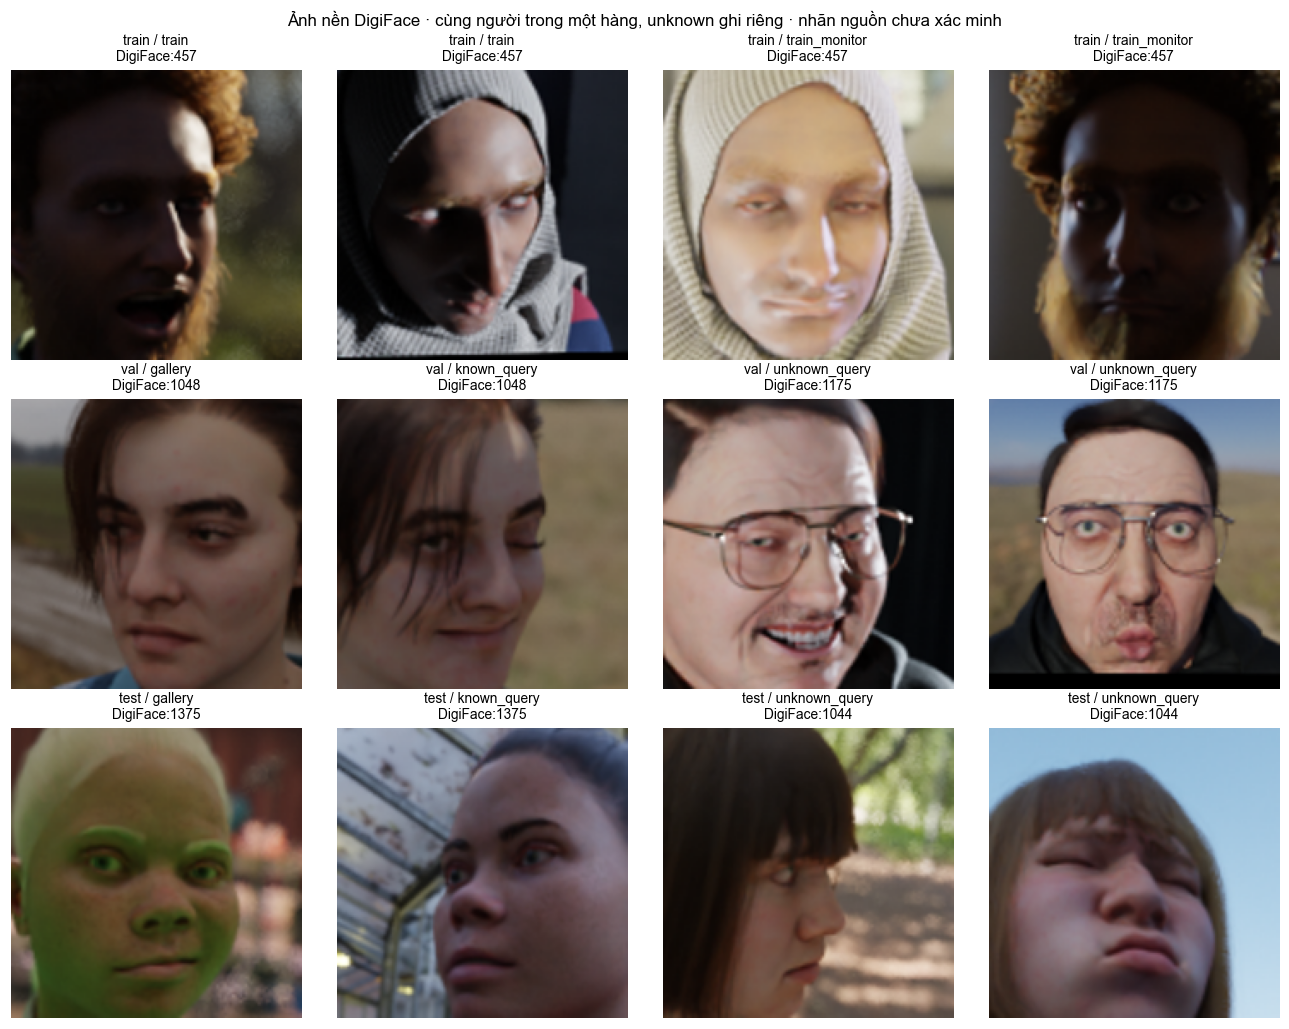

,image_id,path,sha256,canonical_identity,partition,role
0,DF_002057f502ffe894c8be,data/raw/digiface/images_eda/457/61.png,9c1a9465c128498474af0ffe4295002335adac823caffa...,DigiFace:457,train,train
1,DF_d9a9ee1d99d3e7cf7792,data/raw/digiface/images_eda/457/27.png,9b367f7aeae71b3af1fba05c02ceab50fa3b9ade62ffdc...,DigiFace:457,train,train
2,DF_8c09e4971e5f33cdf899,data/raw/digiface/images_eda/457/21.png,818bd513db5174b527073634c4d12b9a39dcfa3987e54b...,DigiFace:457,train,train_monitor
3,DF_f6a4fc59a99d4faca735,data/raw/digiface/images_eda/457/17.png,58fe3e28bb28439f1d23eac397d21011e49f876625f20d...,DigiFace:457,train,train_monitor
4,DF_effb4d4cdddcc994784b,data/raw/digiface/images_eda/1048/52.png,5877419643368ea8e988650ca08009cf3627b486bbb2f5...,DigiFace:1048,val,gallery
5,DF_5d1e44b2bcd3820fdc72,data/raw/digiface/images_eda/1048/36.png,831ffad76bc8529fa155f97d2f4efcdfa47a24b048c10c...,DigiFace:1048,val,known_query
6,DF_b86942b65f0180e8efe6,data/raw/digiface/images_eda/1175/48.png,d021ab0669ce71f6ee7a144ecdf05b2f9763a2780ba5a6...,DigiFace:1175,val,unknown_query
7,DF_c8851dbda148803bd80d,data/raw/digiface/images_eda/1175/44.png,3119b70484518f9b164a1650fa3c1ca3268b2638ac62ed...,DigiFace:1175,val,unknown_query
8,DF_c1e5c537b4046757bdc0,data/raw/digiface/images_eda/1375/49.png,391f204042a057fb3f7854795714e423369263e68ddcbb...,DigiFace:1375,test,gallery
9,DF_f171b1401b0176dd4987,data/raw/digiface/images_eda/1375/26.png,b38f50d76716333d0ad9944d5da4da7bb98df7d9eacc51...,DigiFace:1375,test,known_query


In [17]:
examples=[]
for partition in ['train','val','test']:
    sub=roles[roles.partition.eq(partition)]
    known=sub[sub.identity_role.isin(['training_identity','known'])]
    identity=stable_order(known.canonical_identity,partition+'_illustration')[0]
    person=known[known.canonical_identity.eq(identity)]
    if partition=='train':
        for role in ['train','train_monitor']:
            g=person[person.role.eq(role)]
            for image_id in stable_order(g.image_id,role+'_illustration')[:2]:
                examples.append(g[g.image_id.eq(image_id)].iloc[0].to_dict())
    else:
        for role in ['gallery','known_query']:
            g=person[person.role.eq(role)]
            image_id=stable_order(g.image_id,role+'_illustration')[0]
            examples.append(g[g.image_id.eq(image_id)].iloc[0].to_dict())
        unknown=sub[sub.role.eq('unknown_query')]
        uid=stable_order(unknown.canonical_identity,partition+'_unknown_illustration')[0]
        g=unknown[unknown.canonical_identity.eq(uid)]
        for image_id in stable_order(g.image_id,'unknown_illustration')[:2]:
            examples.append(g[g.image_id.eq(image_id)].iloc[0].to_dict())
examples=pd.DataFrame(examples)
fig,axes=plt.subplots(3,4,figsize=(12,9.5))
for ax,row in zip(axes.flat,examples.itertuples()):
    path=ROOT/row.path
    assert sha(path)==row.sha256,'Ảnh minh họa đổi bytes: '+row.image_id
    with Image.open(path) as im:
        shown=ImageOps.contain(ImageOps.exif_transpose(im).convert('RGB'),(170,170))
        ax.imshow(shown)
    ax.set_title(f'{row.partition} / {row.role}\n{row.canonical_identity}',fontsize=9)
    ax.axis('off')
fig.suptitle('Ảnh nền DigiFace · cùng người trong một hàng, unknown ghi riêng · nhãn nguồn chưa xác minh',fontsize=11)
fig.tight_layout();finish(fig,'10_role_examples')
save(examples[['image_id','path','sha256','canonical_identity','partition','role']], '10_visual_example_selection')

## 12. Xuất protocol có phiên bản và các điều kiện còn mở

Các tệp `*_draft` đủ để nhóm xem chính xác ảnh nào đang ở vai trò nào và để viết loader thí điểm. `frozen=false` ngăn hiểu nhầm đây là split/test đã nghiệm thu. Không tự đổi file thành “final” chỉ vì bộ kiểm kỹ thuật đã pass.

Những việc còn cần bằng chứng riêng: xác nhận các ca nhãn/box và alias; kiểm gallery có mặt rõ; chốt preprocessing trên validation; chốt enrollment failure; thu dữ liệu webcam tách phiên nếu làm demo thực tế. Các quyết định này không thể được xác nhận thay nhóm chỉ bằng hash hay khoảng cách embedding.

In [18]:
pending_decisions=pd.DataFrame([
    ['QA semantic', 'A/C', 'Đọc ca hold/nhãn/box; cập nhật group_decisions.csv có bằng chứng', 'pending'],
    ['Gallery DigiFace', 'A/B', 'Xác nhận chính sách gallery dữ liệu nền hoặc tạo clear-gallery đã QA trước recognition', 'pending'],
    ['ROF gallery/query', 'A/C', 'Đã có vai trò cụ thể; xác nhận clean gallery/semantic trong 07_gallery_review_queue.csv', 'pending_independent_review'],
    ['Alias ROF/MFR2', 'A/C', 'Giữ guard; nếu phân ảnh thật sang calibration phải chia cùng phía', 'pending'],
    ['MFR2 verification', 'C', 'Giữ 848 dòng pairs; chốt cách threshold/fold riêng, không tự gọi fold tạo mới là official', 'pending'],
    ['Enrollment failure', 'B/C', 'Giữ toàn bộ known-query trong mẫu số, log thất bại; không thay ảnh gallery bằng query', 'technical_policy_defined'],
    ['Preprocessing pilot', 'A/B', 'Đủ kiểm kỹ thuật để thử resize/redetect trên validation; không sử dụng test/ROF/MFR2', 'technical_ready'],
    ['Webcam', 'C', 'Thu có đồng thuận; người/phiên calibration và test tách biệt', 'not_started'],
],columns=['decision','owner','required_evidence','status'])
save(pending_decisions,'11_pending_decisions')

input_hashes=dict(zip(fingerprints.key,fingerprints.sha256))
technical_ready=bool(checks.passed.all() and external_checks.passed.all()
    and all(x['detected'] for x in negative_tests+external_negative_tests))
semantic_confirmed=bool(usable.identity_verified_independently.eq('True').all())
gallery_confirmed=bool(gallery_review_queue.verification_status.eq('confirmed_independently').all())
release_gates={
    'technical_split_checks_passed':technical_ready,
    'pilot_validation_preprocessing_allowed':technical_ready,
    'independent_QA_confirmed':semantic_confirmed,'gallery_confirmed':gallery_confirmed,
    'preprocessing_confirmed':False,'official_test_release':False,
    'external_recognition_allowed':False,
}
handoff_schema={
    'version':CONFIG['version'],'status':STATUS,'raw_write_allowed':False,
    'internal_image_roles':'tables/05_image_roles_draft.csv',
    'external_image_roles':'tables/07_external_image_roles_draft.csv',
    'gallery_review_queue':'tables/07_gallery_review_queue.csv',
    'required_columns':['image_id','source','canonical_identity','path','sha256','pixel_sha256',
        'photo_group','leakage_group','guard_group','partition','role','qa_action_proposed','qa_reasons'],
    'loader_pilot_scope':{'allowed_source':'DigiFace','allowed_partition':'val',
        'allowed_roles':['gallery','known_query','unknown_query'],
        'reject_sources':['ROF','MFR2'],'reject_partitions':['train','test','external_test_reserve']},
    'variant_inheritance':['image_id','canonical_identity','partition','photo_group','leakage_group','guard_group'],
    'failure_status_must_not_drop_input':True,
    'human_policy_approval_is_not_semantic_confirmation':True,
    'official_split_frozen':False,
}
write_json(handoff_schema,'handoff_schema.json')
source_nb=json.loads((HERE/'Chia_tap_va_protocol_danh_gia.ipynb').read_text(encoding='utf-8'))
notebook_source_sha=hashlib.sha256(json.dumps(
    [(c['cell_type'],''.join(c['source'])) for c in source_nb['cells']],ensure_ascii=False).encode()).hexdigest()
protocol={
    **CONFIG,'status':STATUS,'input_sha256':input_hashes,
    'notebook_source_sha256':notebook_source_sha,'config_sha256':hashlib.sha256(
        json.dumps(CONFIG,sort_keys=True).encode()).hexdigest(),
    'base_image_count':len(M),'draft_eligible_images':len(usable),'withheld_images':len(excluded),
    'human_decisions_loaded':int(M.group_decision.ne('').sum()),
    'identity_splits':{p:sorted(identity_split[identity_split.partition.eq(p)].canonical_identity) for p in ['train','val','test']},
    'evaluation_contract':evaluation_contract,
    'external_status':'metadata_roles_assigned_draft; no pixel inference, recognition or threshold tuning',
    'rof_allocation':rof_allocation,
    'identity_mapping':'source_namespace; aliases guarded not merged',
    'release_gates':release_gates,
    'artifacts':{'identity_splits':'tables/04_identity_splits_draft.csv',
                 'image_roles':'tables/05_image_roles_draft.csv',
                 'external_reserve':'tables/07_external_test_reserve.csv',
                 'external_roles':'tables/07_external_image_roles_draft.csv',
                 'rof_identity_roles':'tables/07_rof_identity_roles_draft.csv',
                 'gallery_review_queue':'tables/07_gallery_review_queue.csv',
                 'handoff_schema':'handoff_schema.json',
                 'withheld':'tables/02_withheld_draft.csv'},
}
write_json(protocol,'protocol_draft.json')
write_json({'version':CONFIG['version'],'seed':SEED,'frozen':False,
            'manifest_sha256':input_hashes['manifest'],'ids':protocol['identity_splits']},'identity_splits_draft.json')
for row in fingerprints.itertuples():
    assert sha(ROOT/row.path)==row.sha256,'Input thay đổi trong lúc chạy: '+row.key
assert not set(roles.canonical_identity)&set(external.canonical_identity)
assert set(roles.image_id).isdisjoint(external.image_id)
assert set(roles.image_id)|set(external.image_id)|set(excluded.image_id)==set(M.image_id)
artifact_hashes=save(pd.DataFrame([
    {'path':p.relative_to(OUT).as_posix(),'bytes':p.stat().st_size,'sha256':sha(p)}
    for p in sorted(OUT.rglob('*')) if p.is_file() and p.suffix in ['.csv','.png','.svg','.json']
    and p.name not in ['12_artifact_hashes.csv','execution_summary.json']
]),'12_artifact_hashes')
summary={
    'status':STATUS,'checks':'PASS','leakage_assertions':len(checks),
    'negative_tests_detected':len(negative_tests),'row_order_reproducibility':'PASS',
    'external_leakage_assertions':len(external_checks),'external_negative_tests_detected':len(external_negative_tests),
    'external_row_order_reproducibility':'PASS','technical_step3_ready':technical_ready,
    'pilot_validation_preprocessing_allowed':release_gates['pilot_validation_preprocessing_allowed'],
    'gallery_review_queue_images':len(gallery_review_queue),
    'fresh_computation':'split, roles, feasibility, assertions, figures',
    'full_raw_rescan':False,'raw_examples_hash_verified':len(examples),
    'raw_modified':False,'labels_changed':False,'preprocessing_started':False,
    'recognition_evaluated':False,'training_started':False,
    'frozen':False,'source_sha256':notebook_source_sha,
    'input_sha256':input_hashes,'environment':ENV,
    'executed_at_utc':datetime.now(timezone.utc).isoformat(),
    'elapsed_seconds':round(time.perf_counter()-STARTED,3),
}
write_json(summary,'execution_summary.json')
display(pending_decisions)
display(pd.DataFrame([{'check':'Tất cả ảnh có một nơi đến','result':'PASS'},
    {'check':'Identity/hash/group/known-unknown','result':'PASS'},
    {'check':'Trộn thứ tự input vẫn tái lập','result':'PASS'},
    {'check':'Bộ kiểm bắt được lỗi cố tình đưa vào','result':'PASS'},
    {'check':'Xác nhận semantic và gallery của nhóm','result':'PENDING'}]))

,decision,owner,required_evidence,status
0,QA semantic,A/C,Đọc ca hold/nhãn/box; cập nhật group_decisions...,pending
1,Gallery DigiFace,A/B,Xác nhận chính sách gallery dữ liệu nền hoặc t...,pending
2,ROF gallery/query,A/C,Đã có vai trò cụ thể; xác nhận clean gallery/s...,pending_independent_review
3,Alias ROF/MFR2,A/C,Giữ guard; nếu phân ảnh thật sang calibration ...,pending
4,MFR2 verification,C,Giữ 848 dòng pairs; chốt cách threshold/fold r...,pending
5,Enrollment failure,B/C,"Giữ toàn bộ known-query trong mẫu số, log thất...",technical_policy_defined
6,Preprocessing pilot,A/B,Đủ kiểm kỹ thuật để thử resize/redetect trên v...,technical_ready
7,Webcam,C,Thu có đồng thuận; người/phiên calibration và ...,not_started


,check,result
0,Tất cả ảnh có một nơi đến,PASS
1,Identity/hash/group/known-unknown,PASS
2,Trộn thứ tự input vẫn tái lập,PASS
3,Bộ kiểm bắt được lỗi cố tình đưa vào,PASS
4,Xác nhận semantic và gallery của nhóm,PENDING


In [19]:
by_role={(r.partition,r.role):r.images for r in role_summary.itertuples()}
display(Markdown(f"""
## 13. Kết quả và bước kế tiếp

- **{vn(len(M))} ảnh nguồn** được đối chiếu với đầu vào QA; **{vn(len(usable))} ảnh** nằm trong draft, **{vn(len(excluded))} ảnh** cách ly trên danh sách. Tất cả raw vẫn nguyên trạng.
- DigiFace: **{vn(CONFIG['train_identities'])} / {vn(CONFIG['validation_identities'])} / {vn(CONFIG['test_identities'])} identity** train/val/test. Train có **{vn(by_role[('train','train')])} ảnh cập nhật gradient** và **{vn(by_role[('train','train_monitor')])} ảnh monitor**.
- Mỗi val/test: **{vn(by_role[('val','gallery')])} ảnh gallery**, **{vn(by_role[('val','known_query')])} known-query, **{vn(by_role[('val','unknown_query')])} unknown-query. Gallery chưa được xác nhận clean.
- **{vn(len(external))} ảnh thật** dành ngoài tuning. ROF có **{rof_allocation['known_identities']} known / {rof_allocation['actual_unknown_identities']} unknown identity** được chọn theo component; **{rof_allocation['ineligible_identities']} identity** thiếu gallery/query giữ ở reserve. MFR2 giữ protocol cặp riêng; alias chưa được gộp danh tính.
- **{len(checks)} kiểm tra nội bộ + {len(external_checks)} kiểm tra ROF** đạt; **{len(negative_tests)+len(external_negative_tests)} ca cố tình làm sai** được phát hiện; đổi thứ tự input không làm đổi cả split nội bộ lẫn cohort ROF.
- Hàng đợi gallery có **{vn(len(gallery_review_queue))} ảnh cần xác nhận**; không gán xác nhận con người từ các kiểm bằng code. Phần kỹ thuật bước 3 đã đủ để thử preprocessing trên **DigiFace validation**, còn `official_test_release=false`.

**Bước kế tiếp:** dùng validation draft cho preprocessing thí điểm có status rõ ràng, so direct-resize và redetect-crop, đối chiếu tensor/ảnh/mẫu số. Chốt gallery và các quyết định semantic trước kết quả đánh giá xác nhận. Chưa chạy preprocessing hàng loạt, chưa chọn threshold hoặc train B1/B2 trong notebook này.
"""))


## 13. Kết quả và bước kế tiếp

- **86.980 ảnh nguồn** được đối chiếu với đầu vào QA; **86.094 ảnh** nằm trong draft, **886 ảnh** cách ly trên danh sách. Tất cả raw vẫn nguyên trạng.
- DigiFace: **1.600 / 200 / 200 identity** train/val/test. Train có **57.600 ảnh cập nhật gradient** và **6.400 ảnh monitor**.
- Mỗi val/test: **300 ảnh gallery**, **3.700 known-query, **4.000 unknown-query. Gallery chưa được xác nhận clean.
- **6.094 ảnh thật** dành ngoài tuning. ROF có **144 known / 36 unknown identity** được chọn theo component; **2 identity** thiếu gallery/query giữ ở reserve. MFR2 giữ protocol cặp riêng; alias chưa được gộp danh tính.
- **31 kiểm tra nội bộ + 19 kiểm tra ROF** đạt; **6 ca cố tình làm sai** được phát hiện; đổi thứ tự input không làm đổi cả split nội bộ lẫn cohort ROF.
- Hàng đợi gallery có **1.032 ảnh cần xác nhận**; không gán xác nhận con người từ các kiểm bằng code. Phần kỹ thuật bước 3 đã đủ để thử preprocessing trên **DigiFace validation**, còn `official_test_release=false`.

**Bước kế tiếp:** dùng validation draft cho preprocessing thí điểm có status rõ ràng, so direct-resize và redetect-crop, đối chiếu tensor/ảnh/mẫu số. Chốt gallery và các quyết định semantic trước kết quả đánh giá xác nhận. Chưa chạy preprocessing hàng loạt, chưa chọn threshold hoặc train B1/B2 trong notebook này.


## 14. Cách đọc và sử dụng đầu ra

- `tables/04_identity_splits_draft.csv`, `tables/05_image_roles_draft.csv`: danh sách identity và ảnh nội bộ; mọi dòng có trạng thái draft.
- `tables/02_withheld_draft.csv`: ảnh vẫn tồn tại trong raw nhưng được cách ly trong mô phỏng chính sách.
- `tables/06_leakage_assertions.csv`, `06_negative_tests.csv`: bằng chứng kiểm tính đúng và khả năng phát hiện lỗi.
- `tables/07_external_test_reserve.csv`, `07_external_feasibility_*.csv`: ảnh thật dành ngoài tuning và giới hạn gallery.
- `tables/07_rof_image_roles_draft.csv`, `07_rof_identity_roles_draft.csv`: cohort ROF 1:N cụ thể theo metadata, có known/unknown và reserve thiếu điều kiện; chưa chạy ảnh qua model.
- `tables/07_rof_leakage_assertions.csv`, `07_rof_negative_tests.csv`: kiểm rò rỉ toàn cohort và khả năng bắt lỗi.
- `tables/07_gallery_review_queue.csv`: danh sách gallery nội bộ và ROF cần nhóm xem; là output sinh tự động, quyết định người duyệt phải nằm ở input riêng.
- `tables/08_cross_source_alias_guard.csv`, `08_mfr2_*`: các phụ thuộc chưa xác minh và cặp nguồn được giữ nguyên.
- `protocol_draft.json`: cấu hình, seed, hash đầu vào, các release gate và hợp đồng evaluator; `frozen=false`.
- `handoff_schema.json`: hợp đồng loader/biến thể/failure và phạm vi pilot chỉ DigiFace validation, cấm dùng test/external để tuning.
- `execution_summary.json`, `tables/12_artifact_hashes.csv`: lượt tính thực và hash artifact. Tệp kiểm execution do runner ghi là bằng chứng bổ sung, không thay thế summary tự sinh trong notebook.

Khi thay dữ liệu QA/nhóm/decisions: chạy lại QA rồi notebook này. Khi thay chính sách hoặc số gallery: tăng `version`, chạy lại các kiểm trước inference; không giữ threshold cũ mặc định.

Nguồn phương pháp: kế hoạch nội bộ `../huong_dan_trien_khai_hoan_chinh.md`, notebook EDA/QA kèm provenance; [NIST FRTE 1:N](https://pages.nist.gov/frvt/html/frvt1N.html) về identification threshold; [DigiFace-1M](https://github.com/microsoft/DigiFace1M), [ROF](https://github.com/ekremerakin/RealWorldOccludedFaces), [MFR2](https://github.com/aqeelanwar/MaskTheFace) về nguồn dữ liệu. Các bảng trong notebook được tính từ dữ liệu cục bộ, không lấy số công bố làm số đã có.